# Setting up environment
Importing libraries and defining global variables

In [1]:
import os
import typing
from sklearn.gaussian_process.kernels import *
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.model_selection import train_test_split

In [16]:
# Set `EXTENDED_EVALUATION` to `True` in order to visualize your predictions.
EXTENDED_EVALUATION = False
EVALUATION_GRID_POINTS = 300  # Number of grid points used in extended evaluation

# Cost function constants
COST_W_UNDERPREDICT = 50.0
COST_W_NORMAL = 1.0

# Defining Model class

In [17]:
class Model(object):
    """
    Model for this task.
    You need to implement the train_model and generate_predictions methods
    without changing their signatures, but are allowed to create additional methods.
    """

    def __init__(self):
        """
        Initialize your model here.
        We already provide a random number generator for reproducibility.
        """
        self.rng = np.random.default_rng(seed=0)

        # TODO: Add custom initialization for your model here if necessary

    # Don't change the name or the signature of this function
    def predict_pollution_concentration(self, test_coordinates: np.ndarray, test_area_flags: np.ndarray) -> typing.Tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Predict the pollution concentration for a given set of city_areas.
        :param test_coordinates: city_areas as a 2d NumPy float array of shape (NUM_SAMPLES, 2)
        :param test_area_flags: city_area info for every sample in a form of a bool array (NUM_SAMPLES,)
        :return:
            Tuple of three 1d NumPy float arrays, each of shape (NUM_SAMPLES,),
            containing your predictions, the GP posterior mean, and the GP posterior stddev (in that order)
        """

        # TODO: Use your GP to estimate the posterior mean and stddev for each city_area here
        gp_mean = np.zeros(test_coordinates.shape[0], dtype=float)
        gp_std = np.zeros(test_coordinates.shape[0], dtype=float)

        # TODO: Use the GP posterior to form your predictions here
        predictions = gp_mean

        return predictions, gp_mean, gp_std

    # Don't change the name or the signature of this function
    def fit_model_on_training_data(self, train_targets: np.ndarray, train_coordinates: np.ndarray, train_area_flags: np.ndarray):
        """
        Fit your model on the given training data.
        :param train_coordinates: Training features as a 2d NumPy float array of shape (NUM_SAMPLES, 2)
        :param train_targets: Training pollution concentrations as a 1d NumPy float array of shape (NUM_SAMPLES,)
        :param train_area_flags: Binary variable denoting whether the 2D training point is in the residential area (1) or not (0)
        """

        # TODO: Fit your model here
        pass


# Helper functions

In [18]:
# You don't have to change this function
def calculate_cost(ground_truth: np.ndarray, predictions: np.ndarray, area_flags: np.ndarray) -> float:
    """
    Calculates the cost of a set of predictions.

    :param ground_truth: Ground truth pollution levels as a 1d NumPy float array
    :param predictions: Predicted pollution levels as a 1d NumPy float array
    :param area_flags: city_area info for every sample in a form of a bool array (NUM_SAMPLES,)
    :return: Total cost of all predictions as a single float
    """
    assert ground_truth.ndim == 1 and predictions.ndim == 1 and ground_truth.shape == predictions.shape

    # Unweighted cost
    cost = (ground_truth - predictions) ** 2
    weights = np.ones_like(cost) * COST_W_NORMAL

    # Case i): underprediction
    mask = (predictions < ground_truth) & [bool(area_flag) for area_flag in area_flags]
    weights[mask] = COST_W_UNDERPREDICT

    # Weigh the cost and return the average
    return np.mean(cost * weights)

In [19]:
# You don't have to change this function
def check_within_circle(coordinate, circle_parameters):
    """
    Checks if a coordinate is inside a circle.
    :param coordinate: 2D coordinate
    :param circle_parameters: 3D coordinate of the circle center and its radius
    :return: True if the coordinate is inside the circle, False otherwise
    """
    return (coordinate[0] - circle_parameters[0])**2 + (coordinate[1] - circle_parameters[1])**2 < circle_parameters[2]**2

In [20]:
# You don't have to change this function 
def identify_city_area_flags(grid_coordinates):
    """
    Determines the city_area index for each coordinate in the visualization grid.
    :param grid_coordinates: 2D coordinates of the visualization grid
    :return: 1D array of city_area indexes
    """
    # Circles coordinates
    circles = np.array([[0.5488135, 0.71518937, 0.17167342],
                    [0.79915856, 0.46147936, 0.1567626 ],
                    [0.26455561, 0.77423369, 0.10298338],
                    [0.6976312,  0.06022547, 0.04015634],
                    [0.31542835, 0.36371077, 0.17985623],
                    [0.15896958, 0.11037514, 0.07244247],
                    [0.82099323, 0.09710128, 0.08136552],
                    [0.41426299, 0.0641475,  0.04442035],
                    [0.09394051, 0.5759465,  0.08729856],
                    [0.84640867, 0.69947928, 0.04568374],
                    [0.23789282, 0.934214,   0.04039037],
                    [0.82076712, 0.90884372, 0.07434012],
                    [0.09961493, 0.94530153, 0.04755969],
                    [0.88172021, 0.2724369,  0.04483477],
                    [0.9425836,  0.6339977,  0.04979664]])
    
    area_flags = np.zeros((grid_coordinates.shape[0],))

    for i,coordinate in enumerate(grid_coordinates):
        area_flags[i] = any([check_within_circle(coordinate, circ) for circ in circles])

    return area_flags

In [21]:
# Don't change the name or the signature of this function
def perform_extended_model_evaluation(model: Model, output_dir: str = '/results'):
    """
    Visualizes the predictions of a fitted model.
    :param model: Fitted model to be visualized
    :param output_dir: Directory in which the visualizations will be stored
    """
    print('Performing extended evaluation')

    # Visualize on a uniform grid over the entire coordinate system
    grid_lat, grid_lon = np.meshgrid(
        np.linspace(0, EVALUATION_GRID_POINTS - 1, num=EVALUATION_GRID_POINTS) / EVALUATION_GRID_POINTS,
        np.linspace(0, EVALUATION_GRID_POINTS - 1, num=EVALUATION_GRID_POINTS) / EVALUATION_GRID_POINTS,
    )
    visualization_grid = np.stack((grid_lon.flatten(), grid_lat.flatten()), axis=1)
    grid_area_flags = identify_city_area_flags(visualization_grid)
    
    # Obtain predictions, means, and stddevs over the entire map
    predictions, gp_mean, gp_stddev = model.predict_pollution_concentration(visualization_grid, grid_area_flags)
    predictions = np.reshape(predictions, (EVALUATION_GRID_POINTS, EVALUATION_GRID_POINTS))
    gp_mean = np.reshape(gp_mean, (EVALUATION_GRID_POINTS, EVALUATION_GRID_POINTS))

    vmin, vmax = 0.0, 65.0

    # Plot the actual predictions
    fig, ax = plt.subplots()
    ax.set_title('Extended visualization of task 1')
    im = ax.imshow(predictions, vmin=vmin, vmax=vmax)
    cbar = fig.colorbar(im, ax=ax)

    # Save figure to pdf
    figure_path = os.path.join(output_dir, 'extended_evaluation.pdf')
    fig.savefig(figure_path)
    print(f'Saved extended evaluation to {figure_path}')

    plt.show()

In [23]:
# Don't change the name or the signature of this function
def get_city_area_data(train_x: np.ndarray, test_x: np.ndarray) -> typing.Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Extracts the city_area information from the training and test features.
    :param train_x: Training features
    :param test_x: Test features
    :return: Tuple of (training features' 2D coordinates, training features' city_area information,
        test features' 2D coordinates, test features' city_area information)
    """
    train_coordinates = np.zeros((train_x.shape[0], 2), dtype=float)
    train_area_flags = np.zeros((train_x.shape[0],), dtype=bool)
    test_coordinates = np.zeros((test_x.shape[0], 2), dtype=float)
    test_area_flags = np.zeros((test_x.shape[0],), dtype=bool)

    #TODO: Extract the city_area information from the training and test features

    assert train_coordinates.shape[0] == train_area_flags.shape[0] and test_coordinates.shape[0] == test_area_flags.shape[0]
    assert train_coordinates.shape[1] == 2 and test_coordinates.shape[1] == 2
    assert train_area_flags.ndim == 1 and test_area_flags.ndim == 1

    return train_coordinates, train_area_flags, test_coordinates, test_area_flags


# Bayesian Model Selection

In [27]:
# Load the data
train_x_full = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
train_y_full = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)
test_x = np.loadtxt('test_x.csv', delimiter=',', skiprows=1)

subsample_x, _, subsample_y, _ = train_test_split(train_x_full, train_y_full, test_size=.7, random_state=0)

In [28]:
subsample_x.shape

(4556, 3)

In [40]:
import optuna
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, DotProduct, ExpSineSquared
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.model_selection import train_test_split
import numpy as np

def objective(trial: optuna.Trial):
    train_x_full = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
    train_y_full = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)

    subsample_x, _, subsample_y, _ = train_test_split(train_x_full, train_y_full, test_size=0.6, random_state=0)
    train_x, val_x, train_y, val_y = train_test_split(subsample_x, subsample_y, test_size=0.1, random_state=0)

    with_dot = trial.suggest_categorical('with_dot', [True, False])
    kernel = Matern(nu=1.5) + WhiteKernel()

    if with_dot:
        kernel += DotProduct()
    

    gpr = GaussianProcessRegressor(kernel=kernel, random_state=0, normalize_y=True)
    gpr.fit(train_x, train_y)
    pred_mean, pred_std = gpr.predict(val_x, return_std=True)
    scale = trial.suggest_float('scale', 0, 3)

    area_flags = identify_city_area_flags(val_x[:, :2])
    pred = pred_mean + scale*pred_std*area_flags

    accuracy = calculate_cost(val_y, pred, area_flags)

    return accuracy

In [41]:
study = optuna.create_study(study_name="pai1_gpr_4", storage="sqlite:///pai1_gpr.db", direction="minimize", load_if_exists=True)
study.optimize(objective, n_trials=100)

[I 2025-10-16 01:51:47,646] A new study created in RDB with name: pai1_gpr_4
[I 2025-10-16 01:52:57,472] Trial 0 finished with value: 39.97606638277629 and parameters: {'with_dot': True, 'scale': 0.3675270239239701}. Best is trial 0 with value: 39.97606638277629.
[I 2025-10-16 01:53:26,325] Trial 1 finished with value: 21.963002648677335 and parameters: {'with_dot': False, 'scale': 1.1174981277123637}. Best is trial 1 with value: 21.963002648677335.
[I 2025-10-16 01:54:36,497] Trial 2 finished with value: 23.44317466610367 and parameters: {'with_dot': True, 'scale': 0.9526629626727502}. Best is trial 1 with value: 21.963002648677335.
[I 2025-10-16 01:55:05,582] Trial 3 finished with value: 27.79254879184364 and parameters: {'with_dot': False, 'scale': 2.428412076323749}. Best is trial 1 with value: 21.963002648677335.
[I 2025-10-16 01:56:14,672] Trial 4 finished with value: 33.3343506290063 and parameters: {'with_dot': True, 'scale': 2.833306444556846}. Best is trial 1 with value: 21.9

KeyboardInterrupt: 

In [19]:
4556*0.9

4100.400000000001

In [42]:
train_x, val_x, train_y, val_y = train_test_split(train_x_full, train_y_full, test_size=0.1, random_state=0)

gpr = GaussianProcessRegressor(kernel=Matern(nu=1.5) + WhiteKernel() + DotProduct(), random_state=0, normalize_y=True, n_restarts_optimizer=0)
gpr.fit(train_x[:,:2], train_y)
pred_mean, pred_std = gpr.predict(val_x[:,:2], return_std=True)
area_flags = identify_city_area_flags(val_x)
pred = pred_mean + 1.432857955313798*pred_std*area_flags

In [43]:
accuracy = calculate_cost(ground_truth=val_y, predictions=pred, area_flags=area_flags)
accuracy

np.float64(7.587759051687945)

In [12]:
import gpytorch
import torch
import matplotlib.pyplot as plt

train_x_full = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
train_y_full = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)
test_x = np.loadtxt('test_x.csv', delimiter=',', skiprows=1)

train_x, val_x, train_y, val_y = train_test_split(train_x_full, train_y_full, test_size=.1, random_state=0)

class ExactGP(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.MaternKernel() + gpytorch.kernels.ConstantKernel())
    
    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)

        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

train_x = torch.from_numpy(train_x)
train_y = torch.from_numpy(train_y)

likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ExactGP(train_x, train_y, likelihood)

In [136]:
for param_name, param in model.named_parameters():
    print(f'Parameter name: {param_name:42} value = {param.item()}')

Parameter name: likelihood.noise_covar.raw_noise           value = 0.0
Parameter name: mean_module.raw_constant                   value = 0.0
Parameter name: covar_module.raw_outputscale               value = 0.0
Parameter name: covar_module.base_kernel.kernels.0.raw_lengthscale value = 0.0
Parameter name: covar_module.base_kernel.kernels.1.raw_constant value = 0.0


In [15]:
params = [param for _, param in model.named_parameters()]
params[3]

Parameter containing:
tensor([[0.]], requires_grad=True)

In [44]:
model.covar_module.base_kernel

AdditiveKernel(
  (kernels): ModuleList(
    (0): MaternKernel(
      (raw_lengthscale_constraint): Positive()
    )
    (1): ConstantKernel(
      (raw_constant_constraint): Positive()
    )
  )
)

In [16]:
# Find optimal model hyperparameters
import os
smoke_test = ('CI' in os.environ)
training_iter = 2 if smoke_test else 50

model.train()
likelihood.train()

# Use the adam optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)  # Includes GaussianLikelihood parameters

# "Loss" for GPs - the marginal log likelihood
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

for i in range(training_iter):
    # Zero gradients from previous iteration
    optimizer.zero_grad()
    # Output from model
    output = model(train_x)
    # Calc loss and backprop gradients
    loss = -mll(output, train_y)
    loss.backward()
    print('Iter %d/%d - Loss: %.3f   lengthscale: %.3f   noise: %.3f' % (
        i + 1, training_iter, loss.item(),
        params[3].item(),
        model.likelihood.noise.item()
    ))
    optimizer.step()

Iter 1/50 - Loss: 143.457   lengthscale: 0.000   noise: 0.693
Iter 2/50 - Loss: 130.787   lengthscale: -0.100   noise: 0.744
Iter 3/50 - Loss: 119.245   lengthscale: -0.200   noise: 0.798
Iter 4/50 - Loss: 108.716   lengthscale: -0.300   noise: 0.853
Iter 5/50 - Loss: 99.095   lengthscale: -0.400   noise: 0.911
Iter 6/50 - Loss: 90.294   lengthscale: -0.500   noise: 0.969
Iter 7/50 - Loss: 82.240   lengthscale: -0.600   noise: 1.029
Iter 8/50 - Loss: 74.873   lengthscale: -0.700   noise: 1.089
Iter 9/50 - Loss: 68.139   lengthscale: -0.800   noise: 1.149
Iter 10/50 - Loss: 61.989   lengthscale: -0.900   noise: 1.210
Iter 11/50 - Loss: 56.378   lengthscale: -0.999   noise: 1.270
Iter 12/50 - Loss: 51.259   lengthscale: -1.098   noise: 1.329
Iter 13/50 - Loss: 46.593   lengthscale: -1.197   noise: 1.387
Iter 14/50 - Loss: 42.327   lengthscale: -1.296   noise: 1.444
Iter 15/50 - Loss: 38.410   lengthscale: -1.393   noise: 1.500
Iter 16/50 - Loss: 34.812   lengthscale: -1.491   noise: 1.55

In [17]:
model.eval()

ExactGP(
  (likelihood): GaussianLikelihood(
    (noise_covar): HomoskedasticNoise(
      (raw_noise_constraint): GreaterThan(1.000E-04)
    )
  )
  (mean_module): ConstantMean()
  (covar_module): ScaleKernel(
    (base_kernel): AdditiveKernel(
      (kernels): ModuleList(
        (0): MaternKernel(
          (raw_lengthscale_constraint): Positive()
        )
        (1): ConstantKernel(
          (raw_constant_constraint): Positive()
        )
      )
    )
    (raw_outputscale_constraint): Positive()
  )
)

In [ ]:
val_x = torch.from_numpy(val_x)
f_pred = model(val_x)
y_preds = likelihood(model(val_x))

In [ ]:
f_mean = f_pred.mean
f_var = f_pred.variance
f_covar = f_pred.covariance_matrix

NameError: name 'f_pred' is not defined

In [ ]:
pred = f_mean.detach().numpy()
val_x_n = val_x.numpy()
# val_y_n = val_y.numpy()
val_y_n = val_y

In [ ]:
area_flags = identify_city_area_flags(val_x_n)
accuracy = calculate_cost(ground_truth=val_y_n, predictions=pred, area_flags=area_flags)
accuracy

np.float64(110.64561119047933)

In [104]:
import gpflow
from scipy.cluster.vq import kmeans

train_x, val_x, train_y, val_y = train_test_split(subsample_x, subsample_y, test_size=0.2, random_state=0)
train_y = train_y.reshape(len(train_y),1)

n_inducing = 200
inducing_variable, _ = kmeans(train_x, n_inducing)

model = gpflow.models.SGPR((train_x, train_y), kernel=gpflow.kernels.RBF(), inducing_variable=inducing_variable)

In [105]:
opt = gpflow.optimizers.Scipy()
opt.minimize(model.training_loss, model.trainable_variables)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 19135.46880751767
        x: [-8.052e-01 -3.471e-01 ...  9.704e+01  1.253e+02]
      nit: 762
      jac: [-7.002e-19 -5.681e-21 ...  7.920e-01 -9.596e-01]
     nfev: 878
     njev: 878
 hess_inv: <603x603 LbfgsInvHessProduct with dtype=float64>

In [106]:
pred_mean = model.predict_y(val_x)
pred_mean = np.array(pred_mean)[0,:,:].reshape(1215,)

In [12]:
area_flags = identify_city_area_flags(val_x[:, :2])
accuracy = calculate_cost(val_y, pred_mean, area_flags)
accuracy

np.float64(33.11760349442942)

In [5]:
sample_x = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
sample_y = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)

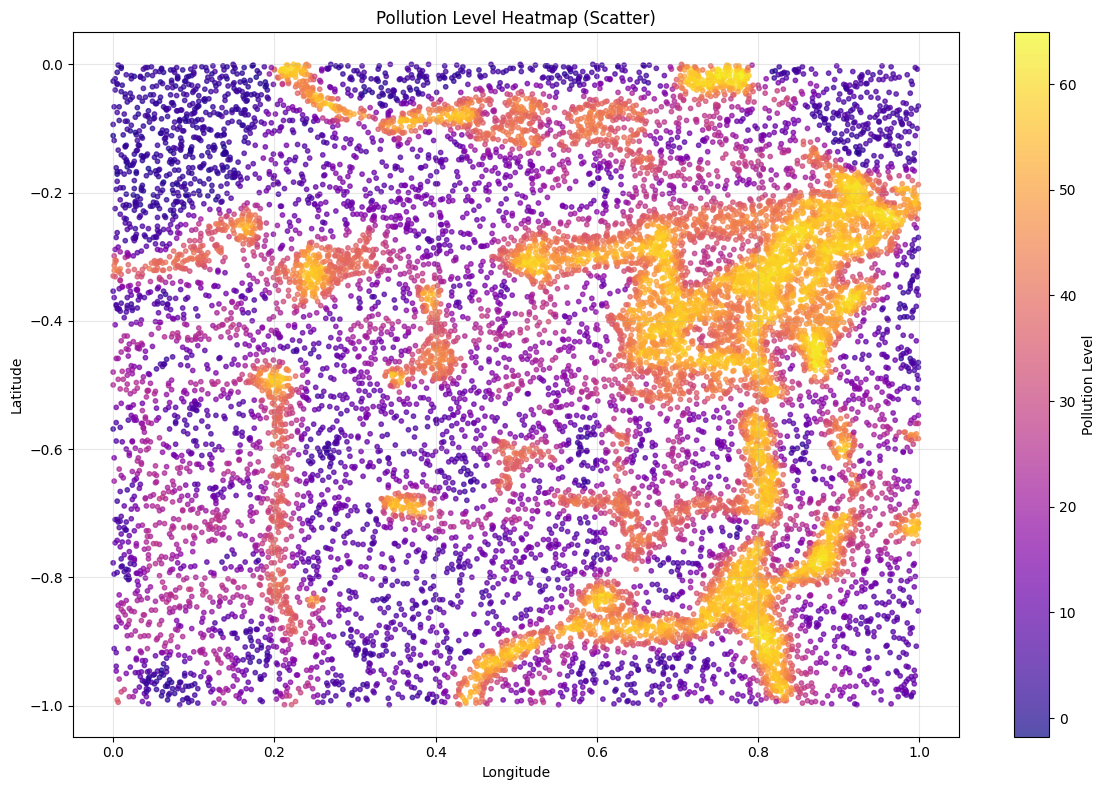

In [7]:
# Create scatter heatmap
plt.figure(figsize=(12, 8))
scatter = plt.scatter(sample_x[:,1], -sample_x[:,0], c=sample_y, 
                     cmap='plasma', s=10, alpha=0.7)

# Add colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Pollution Level')

# Add labels and title
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Pollution Level Heatmap (Scatter)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

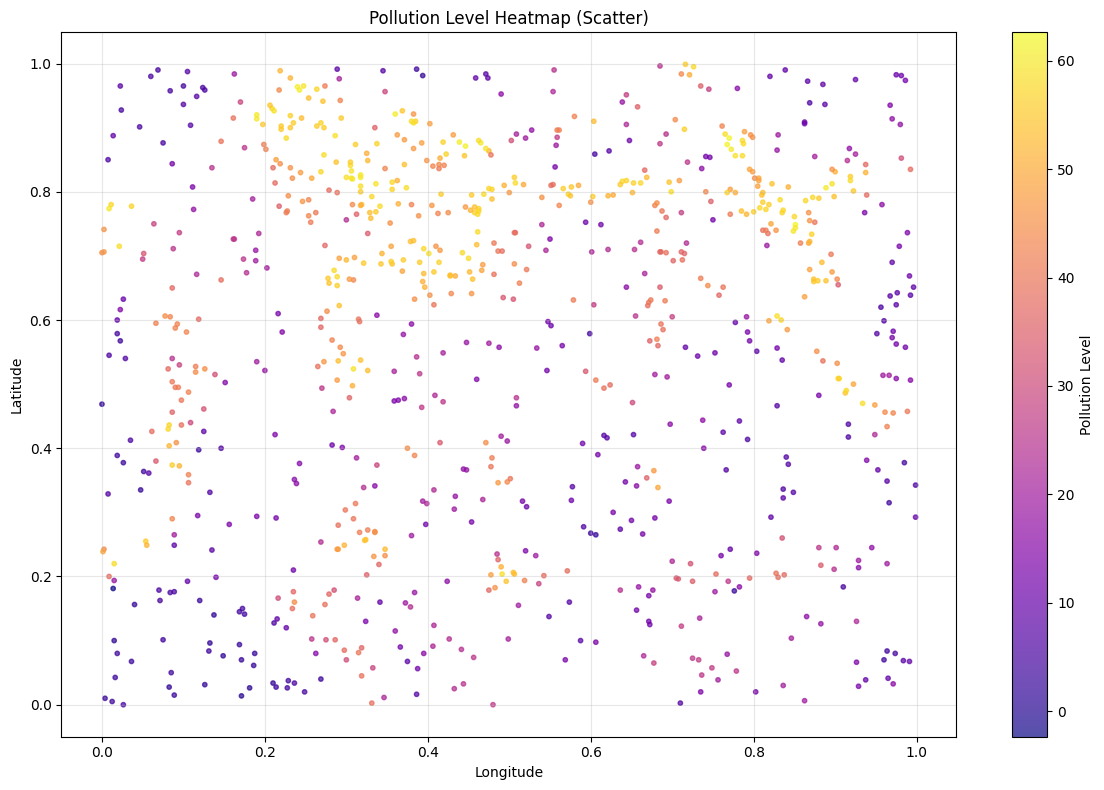

In [25]:
# Create scatter heatmap
plt.figure(figsize=(12, 8))
scatter = plt.scatter(val_x[:,0], val_x[:,1], c=pred_mean, 
                     cmap='plasma', s=10, alpha=0.7)

# Add colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Pollution Level')

# Add labels and title
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Pollution Level Heatmap (Scatter)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Main training loop

Training model
Predicting on test features
(array([0., 0., 0., ..., 0., 0., 0.]), array([0., 0., 0., ..., 0., 0., 0.]), array([0., 0., 0., ..., 0., 0., 0.]))
Performing extended evaluation
Saved extended evaluation to .\extended_evaluation.pdf


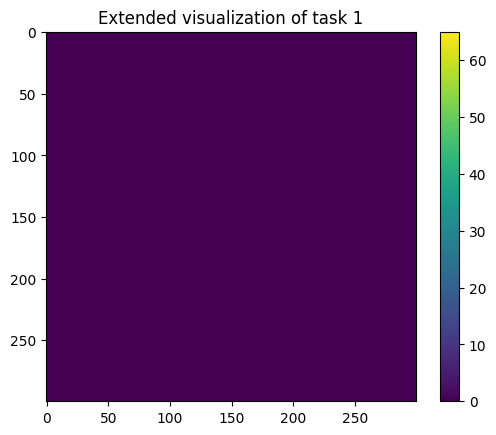

In [ ]:
# you don't have to change this function
def main():
    # Load the training dateset and test features
    train_x = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
    train_y = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)
    test_x = np.loadtxt('test_x.csv', delimiter=',', skiprows=1)

    # creating a subsample for initial testing
    subsample_x, _, subsample_y, _ = train_test_split(train_x, train_y, test_size=.75, random_state=0)

    # Extract the city_area information
    train_coordinates, train_area_flags, test_coordinates, test_area_flags = get_city_area_data(subsample_x, subsample_y)
    
    # Fit the model
    print('Training model')
    model = Model()
    model.fit_model_on_training_data(subsample_y, train_coordinates, train_area_flags)

    # Predict on the test features
    print('Predicting on test features')
    predictions = model.predict_pollution_concentration(test_coordinates, test_area_flags)
    print(predictions)

    if EXTENDED_EVALUATION:
        perform_extended_model_evaluation(model, output_dir='.')


if __name__ == "__main__":
    main()
